In [8]:
"""
Notebook based on https://github.com/tensorflow/models/blob/master/research/object_detection/colab_tutorials/inference_tf2_colab.ipynb


"""

import matplotlib
import matplotlib.pyplot as plt

import io
import os
import scipy.misc
import numpy as np
from six import BytesIO
from PIL import Image, ImageDraw, ImageFont

import tensorflow as tf

from object_detection.utils import label_map_util
from object_detection.utils import config_util
from object_detection.utils import visualization_utils as viz_utils
from object_detection.builders import model_builder

%matplotlib inline

In [9]:
def load_image_into_numpy_array(path):
    """Load an image from file into a numpy array.
    Puts image into numpy array to feed into tensorflow graph.
    Note that by convention we put it into a numpy array with shape
    (height, width, channels), where channels=3 for RGB.
    Args:
      path: the file path to the image
    Returns:
      uint8 numpy array with shape (img_height, img_width, 3)
    """
    img_data = tf.io.gfile.GFile(path, 'rb').read()
    image = Image.open(BytesIO(img_data))
    (im_width, im_height) = image.size
    return np.array(image.getdata()).reshape(
        (im_height, im_width, 3)).astype(np.uint8)
def get_keypoint_tuples(eval_config):
    """Return a tuple list of keypoint edges from the eval config.
    
    Args:
    eval_config: an eval config containing the keypoint edges
    
    Returns:
    a list of edge tuples, each in the format (start, end)
    """
    tuple_list = []
    kp_list = eval_config.keypoint_edge
    for edge in kp_list:
        tuple_list.append((edge.start, edge.end))
    return tuple_list

In [10]:
! dir ..\\exported-models\\package_centernet_resnet

 El volumen de la unidad G es Google Drive
 El nÃºmero de serie del volumen es: 1983-1116

 Directorio de G:\Mi unidad\Newral\repos\nibble_box_tracking\training_demo\exported-models\package_centernet_resnet

30/03/2021  11:55    <DIR>          .
27/03/2021  09:09    <DIR>          ..
26/03/2021  10:05             2.743 pipeline.config
27/03/2021  09:09    <DIR>          checkpoint
27/03/2021  09:09    <DIR>          saved_model
30/03/2021  11:52             2.793 pipeline_mep.config
30/03/2021  11:54             2.793 pipeline_v_mep.config
               3 archivos          8.329 bytes
               4 dirs  64.850.784.256 bytes libres


In [11]:
#This must be changed by new user
pipeline_config = "../exported-models/package_centernet_resnet/pipeline_v_mep.config"
model_dir = '../exported-models/package_centernet_resnet/checkpoint/'

# Load pipeline config and build a detection model
configs = config_util.get_configs_from_pipeline_file(pipeline_config)
model_config = configs['model']
detection_model = model_builder.build(
      model_config=model_config, is_training=False)

# Restore checkpoint
ckpt = tf.compat.v2.train.Checkpoint(
      model=detection_model)
ckpt.restore(os.path.join(model_dir, 'ckpt-0')).expect_partial()

def get_model_detection_function(model):
    """Get a tf.function for detection."""
    
    @tf.function
    def detect_fn(image):
        """Detect objects in image."""

        image, shapes = model.preprocess(image)
        prediction_dict = model.predict(image, shapes)
        detections = model.postprocess(prediction_dict, shapes)

        return detections, prediction_dict, tf.reshape(shapes, [-1])

    return detect_fn

detect_fn = get_model_detection_function(detection_model)

In [12]:
label_map_path = configs['eval_input_config'].label_map_path
label_map = label_map_util.load_labelmap(label_map_path)
categories = label_map_util.convert_label_map_to_categories(
    label_map,
    max_num_classes=label_map_util.get_max_label_map_index(label_map),
    use_display_name=True)
category_index = label_map_util.create_category_index(categories)
label_map_dict = label_map_util.get_label_map_dict(label_map, use_display_name=True)

Image

In [13]:
#val_image: G:\Mi unidad\Newral\repos\nibble_box_tracking\data\processed\getty_ann\boxes\train

In [14]:
image_path = "G:\\Mi unidad\\Newral\\repos\\nibble_box_tracking\\data\\processed\\getty_ann\\boxes\\train\\gettyimages-477008982-640_adpp.mp4_frame450.jpg"
image_np = load_image_into_numpy_array(image_path)

In [15]:
image_np.shape

(360, 640, 3)

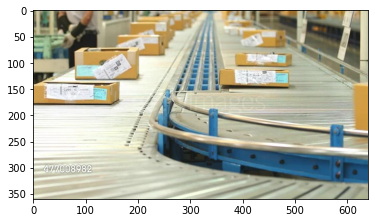

In [16]:
plt.imshow(image_np)

In [17]:
np.expand_dims(image_np, 0).shape

(1, 360, 640, 3)

In [18]:
input_tensor = tf.convert_to_tensor(
    np.expand_dims(image_np, 0), dtype=tf.float32)

In [19]:
input_tensor.shape

TensorShape([1, 360, 640, 3])

In [20]:
detections, predictions_dict, shapes = detect_fn(input_tensor)

ValueError: in user code:

    <ipython-input-11-0b3f3cf38812>:24 detect_fn  *
        prediction_dict = model.predict(image, shapes)
    C:\Users\marcu\anaconda3\envs\nib_box_track\lib\site-packages\object_detection\meta_architectures\center_net_meta_arch.py:3288 predict  *
        predictions[head_name] = [
    C:\Users\marcu\AppData\Roaming\Python\Python37\site-packages\tensorflow\python\keras\engine\base_layer.py:927 __call__  **
        outputs = call_fn(cast_inputs, *args, **kwargs)
    C:\Users\marcu\AppData\Roaming\Python\Python37\site-packages\tensorflow\python\keras\engine\sequential.py:291 call
        outputs = layer(inputs, **kwargs)
    C:\Users\marcu\AppData\Roaming\Python\Python37\site-packages\tensorflow\python\keras\engine\base_layer.py:897 __call__
        self._maybe_build(inputs)
    C:\Users\marcu\AppData\Roaming\Python\Python37\site-packages\tensorflow\python\keras\engine\base_layer.py:2416 _maybe_build
        self.build(input_shapes)  # pylint:disable=not-calla

In [34]:
image

NameError: name 'image' is not defined

In [82]:
shapes

<tf.Tensor: shape=(1, 3), dtype=int32, numpy=array([[288, 512,   3]])>

In [83]:
reshape

<tf.Tensor: shape=(3,), dtype=int32, numpy=array([288, 512,   3])>

In [13]:
label_id_offset = 1
image_np_with_detections = image_np.copy()

# Use keypoints if available in detections
keypoints, keypoint_scores = None, None
if 'detection_keypoints' in detections:
  keypoints = detections['detection_keypoints'][0].numpy()
  keypoint_scores = detections['detection_keypoint_scores'][0].numpy()

viz_utils.visualize_boxes_and_labels_on_image_array(
      image_np_with_detections,
      detections['detection_boxes'][0].numpy(),
      (detections['detection_classes'][0].numpy() + label_id_offset).astype(int),
      detections['detection_scores'][0].numpy(),
      category_index,
      use_normalized_coordinates=True,
      max_boxes_to_draw=200,
      min_score_thresh=.30,
      agnostic_mode=False,
      keypoints=keypoints,
      keypoint_scores=keypoint_scores,
      keypoint_edges=get_keypoint_tuples(configs['eval_config']))

plt.figure(figsize=(12,16))
plt.imshow(image_np_with_detections)
plt.show()

NameError: name 'detections' is not defined